<a href="https://colab.research.google.com/github/Supan-Roy/financial-scam-analysis/blob/main/notebooks/06_transformer_based_modeling.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# Transformer-Based Financial Scam Narrative Classification

## 1. Research Objective

This notebook investigates pretrained Transformer-based language models for multi-level financial scam narrative analysis.

The primary objective is to investigate whether contextual language representations can improve classification performance and cross-generation robustness compared with the traditional TF-IDF-based machine-learning baselines established in the previous experiments.

### Research Tasks

1. Scam subtype classification
2. Fraudulent intent classification
3. Social-engineering tactic recognition

### Experimental Approach

- Begin with a pretrained Transformer model as the initial baseline.
- Fine-tune the model using the existing synthetic datasets.
- Evaluate performance on both V3.1 and LLM-authored test distributions.
- Compare Transformer results against the traditional machine-learning baselines.
- Investigate classification errors and model interpretability.

### Initial Model

DistilBERT will be investigated as the starting pretrained Transformer architecture.

The model choice and architecture may be revised based on experimental findings.

### Experimental Considerations

- Preserve the established dataset partitions.
- Avoid train-test leakage.
- Maintain consistent evaluation metrics.
- Distinguish synthetic cross-generation performance from real-world generalization.
- Document model configurations, hyperparameters and limitations.


In [1]:
# Authenticate with GitHub from the Colab runtime

from google.colab import auth
auth.authenticate_user()

In [2]:
# Clone the private research repository using Colab Secrets

from google.colab import userdata
import subprocess

github_token = userdata.get("GITHUB_TOKEN")

repo_url = (
    "https://x-access-token:"
    + github_token
    + "@github.com/Supan-Roy/financial-scam-analysis.git"
)

subprocess.run(
    ["git", "clone", repo_url],
    check=True
)

print("Private repository cloned successfully.")

Private repository cloned successfully.


In [3]:
# Verify the processed research datasets

from pathlib import Path

PROJECT_ROOT = Path("/content/financial-scam-analysis")

V31_PATH = PROJECT_ROOT / "data/processed/synthetic_financial_scams_v3_1_processed.csv"
LLM_PATH = PROJECT_ROOT / "data/processed/llm_authored_financial_scams_processed.csv"

print("V3.1 dataset exists:", V31_PATH.exists())
print("LLM-authored dataset exists:", LLM_PATH.exists())

if V31_PATH.exists() and LLM_PATH.exists():
    print("\nBoth datasets are available.")
else:
    print("\nWarning: One or more datasets are missing.")

V3.1 dataset exists: True
LLM-authored dataset exists: True

Both datasets are available.


In [4]:
# Load both datasets and inspect their existing structure

import pandas as pd
import numpy as np
import random
import torch

RANDOM_STATE = 42

random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)

df_v31 = pd.read_csv(V31_PATH)
df_llm = pd.read_csv(LLM_PATH)

print("V3.1 dataset:", df_v31.shape)
print("LLM-authored dataset:", df_llm.shape)

print("\nV3.1 partition distribution:")
print(df_v31["split_partition"].value_counts())

print("\nLLM-authored partition distribution:")
print(df_llm["split_partition"].value_counts())

V3.1 dataset: (7800, 36)
LLM-authored dataset: (2730, 45)

V3.1 partition distribution:
split_partition
train    6240
val       780
test      780
Name: count, dtype: int64

LLM-authored partition distribution:
split_partition
train    2184
val       273
test      273
Name: count, dtype: int64


In [5]:
# Inspect target labels and their distributions

target_columns = [
    "scam_subtype",
    "fraudulent_intent",
    "social_engineering_tactics"
]

for dataset_name, df in [
    ("V3.1", df_v31),
    ("LLM-authored", df_llm)
]:
    print(f"\n{'=' * 60}")
    print(dataset_name)

    for column in target_columns:
        print(f"\n{column}")
        print("Missing:", df[column].isna().sum())
        print("Unique labels:", df[column].nunique())

        if column != "social_engineering_tactics":
            print(df[column].value_counts())


V3.1

scam_subtype
Missing: 0
Unique labels: 13
scam_subtype
account_verification              600
card_transaction_alert            600
refund_chargeback                 600
invoice_payment_request           600
loan_offer                        600
investment_crypto                 600
prize_reward                      600
tax_payment                       600
job_task_commission               600
romance_financial_manipulation    600
family_emergency_request          600
recovery_support                  600
charity_donation                  600
Name: count, dtype: int64

fraudulent_intent
Missing: 0
Unique labels: 5
fraudulent_intent
induce_payment_or_transfer                  3684
obtain_personal_or_financial_information    1792
obtain_credentials_or_codes                 1160
gain_account_or_device_access                582
induce_fraudulent_investment                 582
Name: count, dtype: int64

social_engineering_tactics
Missing: 0
Unique labels: 223

LLM-authored

scam_subt

In [6]:
# Mount Google Drive for accessing large research datasets

from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [7]:
# Load binary classification partitions from Google Drive

BINARY_DATA_PATH = (
    Path("/content/drive/MyDrive/financial-scam-analysis/data/splits")
)

TRAIN_PATH = BINARY_DATA_PATH / "train.csv"
VAL_PATH = BINARY_DATA_PATH / "validation.csv"
TEST_PATH = BINARY_DATA_PATH / "test.csv"

train_binary = pd.read_csv(TRAIN_PATH, low_memory=False)
val_binary = pd.read_csv(VAL_PATH, low_memory=False)
test_binary = pd.read_csv(TEST_PATH, low_memory=False)

print(train_binary.shape)
print(val_binary.shape)
print(test_binary.shape)

(60957, 32)
(7618, 32)
(7618, 32)


In [8]:
# Identify the column with mixed data types

mixed_column = train_binary.columns[13]

print("Column index:", 13)
print("Column name:", mixed_column)
print("\nData types found:")
print(train_binary[mixed_column].apply(type).value_counts())

print("\nSample values:")
print(train_binary[mixed_column].dropna().head(10).tolist())

Column index: 13
Column name: scam_subtype

Data types found:
scam_subtype
<class 'float'>    49866
<class 'str'>      11091
Name: count, dtype: int64

Sample values:
['financial_scam', 'financial_scam', 'financial_scam', 'financial_scam', 'financial_scam', 'financial_scam', 'financial_scam', 'financial_scam', 'financial_scam', 'financial_scam']


In [9]:
# Verify binary labels and required text columns

for name, data in [
    ("Train", train_binary),
    ("Validation", val_binary),
    ("Test", test_binary)
]:
    print(f"\n{name}")
    print("Label distribution:")
    print(data["label"].value_counts().sort_index())
    print("Missing labels:", data["label"].isna().sum())
    print("Missing text:", data["normalized_text"].isna().sum())
    print("Empty text:", data["normalized_text"].fillna("").str.strip().eq("").sum())


Train
Label distribution:
label
0    49866
1    11091
Name: count, dtype: int64
Missing labels: 0
Missing text: 0
Empty text: 0

Validation
Label distribution:
label
0    6233
1    1385
Name: count, dtype: int64
Missing labels: 0
Missing text: 0
Empty text: 0

Test
Label distribution:
label
0    6233
1    1385
Name: count, dtype: int64
Missing labels: 0
Missing text: 0
Empty text: 0


In [10]:
# Verify PyTorch and available GPU hardware

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA version:", torch.version.cuda)
else:
    print("No GPU detected. Enable a GPU through Runtime > Change runtime type.")

PyTorch version: 2.14.1+cu130
CUDA available: True
GPU: Tesla T4
CUDA version: 13.0


In [11]:
# Install Hugging Face Transformer and evaluation dependencies

%pip install -q transformers datasets accelerate evaluate scikit-learn

In [12]:
# Verify Transformer dependencies

import torch
import transformers
import datasets
import accelerate
import sklearn

print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("Datasets:", datasets.__version__)
print("Accelerate:", accelerate.__version__)
print("Scikit-learn:", sklearn.__version__)
print("GPU available:", torch.cuda.is_available())

PyTorch: 2.14.1+cu130
Transformers: 5.22.1
Datasets: 4.8.5
Accelerate: 1.15.0
Scikit-learn: 1.6.1
GPU available: True


In [13]:
# Verify dataset availability and Transformer components

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer
)

required_variables = [
    "train_binary",
    "val_binary",
    "test_binary",
    "df_v31",
    "df_llm"
]

for name in required_variables:
    print(f"{name}: {'Available' if name in globals() else 'Not loaded'}")

print("\nTransformer components imported successfully.")
print("GPU:", torch.cuda.get_device_name(0))

train_binary: Available
val_binary: Available
test_binary: Available
df_v31: Available
df_llm: Available

Transformer components imported successfully.
GPU: Tesla T4


In [14]:
# Load the pretrained DistilBERT tokenizer

from transformers import AutoTokenizer

MODEL_NAME = "distilbert/distilbert-base-uncased"
MAX_LENGTH = 256

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

print("Tokenizer loaded successfully.")
print("Model:", MODEL_NAME)
print("Vocabulary size:", tokenizer.vocab_size)
print("Maximum sequence length:", MAX_LENGTH)

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Tokenizer loaded successfully.
Model: distilbert/distilbert-base-uncased
Vocabulary size: 30522
Maximum sequence length: 256


In [17]:
# Analyze DistilBERT token lengths across binary training messages

from tqdm.auto import tqdm

token_lengths = []

for text in tqdm(train_binary["normalized_text"], desc="Tokenizing messages"):
    token_lengths.append(
        len(tokenizer.encode(text, add_special_tokens=True, truncation=False))
    )

token_lengths = np.array(token_lengths)

print("Total messages:", len(token_lengths))
print("Mean tokens:", round(token_lengths.mean(), 2))
print("Median tokens:", int(np.median(token_lengths)))
print("95th percentile:", int(np.percentile(token_lengths, 95)))
print("99th percentile:", int(np.percentile(token_lengths, 99)))
print("Maximum tokens:", int(token_lengths.max()))

for limit in [128, 256, 384, 512]:
    coverage = (token_lengths <= limit).mean() * 100
    print(f"Coverage at {limit} tokens: {coverage:.2f}%")

Tokenizing messages:   0%|          | 0/60957 [00:00<?, ?it/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (711 > 512). Running this sequence through the model will result in indexing errors


Total messages: 60957
Mean tokens: 278.38
Median tokens: 180
95th percentile: 868
99th percentile: 1284
Maximum tokens: 29391
Coverage at 128 tokens: 40.73%
Coverage at 256 tokens: 61.51%
Coverage at 384 tokens: 74.44%
Coverage at 512 tokens: 82.89%


In [18]:
# Inspect the longest messages in the binary training dataset

length_df = pd.DataFrame({
    "token_length": token_lengths,
    "text": train_binary["normalized_text"].values,
    "label": train_binary["label"].values
})

longest_messages = length_df.nlargest(10, "token_length")

for index, row in longest_messages.iterrows():
    print("=" * 80)
    print(
        f"Length: {row['token_length']} tokens | "
        f"Label: {row['label']}"
    )
    print("Beginning:", row["text"][:500])
    print("Ending:", row["text"][-500:])

Length: 29391 tokens | Label: 1
Beginning: BUSINESS PROPOSER REQUESTING CHANGE OF OWNERSHIP ATTENTION


DEAR SIR.

Mr.Dddddddd Rrrrr



I am sending you this fax for a purpose that can favour both of us Sir. I 
konw  this mail may be a surprise to you cause we have not mait before. But 
have Sir what i am going to shear  here with you is not a child game neither 
i am trying to dub you and i will only want you to beleive this purpose 
cause it min not come again.

What we have here is a consignment that contain ( 20.00000Million DL) 
twe
Ending: he people 
in charge of this Money with this contact.

Email> ( [EMAIL_ADDRESS])
Email> ( [EMAIL_ADDRESS])

Personal email contact is

Email> ( [EMAIL_ADDRESS])

So hope to hear from you soon as porsible Sir. You can only contact this 
people through mail first before their phone contact. Till then thanks you 
and god bless.

BEST REGARD

SINCAERLY

Mr. Micheal Ado?

_________________________________________________________________
Add photos t

In [21]:
# Analyze token-length distribution separately for scam and legitimate messages

length_analysis = pd.DataFrame({
    "token_length": token_lengths,
    "label": train_binary["label"].values
})

length_analysis.groupby("label")["token_length"].agg(
    ["count", "mean", "median", "min", "max"]
).round(2)

,count,mean,median,min,max
label,,,,,
0,49866,301.81,211.0,4,7119
1,11091,173.07,44.0,4,29391


In [20]:
# Compare truncation coverage for scam and legitimate messages

length_analysis.groupby("label")["token_length"].agg(
    total="count",
    within_256=lambda x: (x <= 256).sum(),
    within_512=lambda x: (x <= 512).sum(),
    over_512=lambda x: (x > 512).sum()
).assign(
    within_256_pct=lambda x: (x["within_256"] / x["total"] * 100).round(2),
    within_512_pct=lambda x: (x["within_512"] / x["total"] * 100).round(2),
    over_512_pct=lambda x: (x["over_512"] / x["total"] * 100).round(2)
)

,total,within_256,within_512,over_512,within_256_pct,within_512_pct,over_512_pct
label,,,,,,,
0,49866,28812,40988,8878,57.78,82.20,17.80
1,11091,8683,9541,1550,78.29,86.02,13.98


In [22]:
# Prepare and tokenize the binary classification datasets

from datasets import Dataset

MAX_LENGTH = 512

train_dataset = Dataset.from_pandas(
    train_binary[["normalized_text", "label"]].rename(
        columns={"normalized_text": "text"}
    ),
    preserve_index=False
)

val_dataset = Dataset.from_pandas(
    val_binary[["normalized_text", "label"]].rename(
        columns={"normalized_text": "text"}
    ),
    preserve_index=False
)

test_dataset = Dataset.from_pandas(
    test_binary[["normalized_text", "label"]].rename(
        columns={"normalized_text": "text"}
    ),
    preserve_index=False
)

def tokenize_batch(batch):
    return tokenizer(
        batch["text"],
        truncation=True,
        max_length=MAX_LENGTH
    )

train_dataset = train_dataset.map(
    tokenize_batch,
    batched=True,
    remove_columns=["text"]
)

val_dataset = val_dataset.map(
    tokenize_batch,
    batched=True,
    remove_columns=["text"]
)

test_dataset = test_dataset.map(
    tokenize_batch,
    batched=True,
    remove_columns=["text"]
)

print("Tokenization completed.")
print("Train:", train_dataset)
print("Validation:", val_dataset)
print("Test:", test_dataset)

Map:   0%|          | 0/60957 [00:00<?, ? examples/s]

Map:   0%|          | 0/7618 [00:00<?, ? examples/s]

Map:   0%|          | 0/7618 [00:00<?, ? examples/s]

Tokenization completed.
Train: Dataset({
    features: ['label', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 60957
})
Validation: Dataset({
    features: ['label', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 7618
})
Test: Dataset({
    features: ['label', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 7618
})


In [23]:
# Configure dynamic padding and binary classification evaluation metrics

from transformers import DataCollatorWithPadding
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    average_precision_score
)

data_collator = DataCollatorWithPadding(
    tokenizer=tokenizer,
    pad_to_multiple_of=8
)

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    probabilities = torch.softmax(torch.tensor(logits), dim=1).numpy()
    predictions = np.argmax(probabilities, axis=1)

    precision, recall, f1, _ = precision_recall_fscore_support(
        labels,
        predictions,
        average="binary",
        pos_label=1,
        zero_division=0
    )

    _, _, macro_f1, _ = precision_recall_fscore_support(
        labels,
        predictions,
        average="macro",
        zero_division=0
    )

    return {
        "accuracy": accuracy_score(labels, predictions),
        "scam_precision": precision,
        "scam_recall": recall,
        "scam_f1": f1,
        "macro_f1": macro_f1,
        "pr_auc": average_precision_score(labels, probabilities[:, 1])
    }

print("Dynamic padding and evaluation metrics configured.")

Dynamic padding and evaluation metrics configured.


In [24]:
# Initialize the DistilBERT binary classification model

id2label = {
    0: "LEGITIMATE",
    1: "SCAM"
}

label2id = {
    "LEGITIMATE": 0,
    "SCAM": 1
}

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2,
    id2label=id2label,
    label2id=label2id
)

model.config.problem_type = "single_label_classification"

print("Model initialized:", MODEL_NAME)
print("Parameters:", f"{model.num_parameters():,}")
print("GPU available:", torch.cuda.is_available())

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Model initialized: distilbert/distilbert-base-uncased
Parameters: 66,955,010
GPU available: True


In [25]:
# Configure DistilBERT fine-tuning parameters

training_args = TrainingArguments(
    output_dir=str(PROJECT_ROOT / "outputs" / "distilbert_binary"),
    num_train_epochs=3,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    learning_rate=2e-5,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    greater_is_better=True,
    logging_strategy="steps",
    logging_steps=100,
    save_total_limit=2,
    fp16=True,
    report_to="none",
    seed=RANDOM_STATE,
    data_seed=RANDOM_STATE
)

print("Training configuration ready.")
print("Epochs:", training_args.num_train_epochs)
print("Training batch size:", training_args.per_device_train_batch_size)
print("Learning rate:", training_args.learning_rate)
print("Mixed precision:", training_args.fp16)

Training configuration ready.
Epochs: 3
Training batch size: 16
Learning rate: 2e-05
Mixed precision: True


In [26]:
# Initialize the Hugging Face Trainer for binary classification

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    processing_class=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics
)

print("Trainer initialized successfully.")
print("Training examples:", len(train_dataset))
print("Validation examples:", len(val_dataset))
print("Evaluation metric: macro_f1")

Trainer initialized successfully.
Training examples: 60957
Validation examples: 7618
Evaluation metric: macro_f1


In [27]:
# Fine-tune DistilBERT on the real financial scam classification dataset

train_result = trainer.train()

print("\nTraining completed.")
print("Training loss:", train_result.training_loss)
print("Best checkpoint:", trainer.state.best_model_checkpoint)
print("Best validation macro F1:", trainer.state.best_metric)

Epoch,Training Loss,Validation Loss,Accuracy,Scam Precision,Scam Recall,Scam F1,Macro F1,Pr Auc
1,0.018057,0.002817,0.998950,0.997831,0.996390,0.997110,0.998234,0.999980
2,0.006999,0.006601,0.998687,0.993539,0.999278,0.996400,0.997799,0.999921
3,0.000009,0.005971,0.999081,0.995683,0.999278,0.997477,0.998458,0.999967


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Training completed.
Training loss: 0.008494181223541123
Best checkpoint: /content/financial-scam-analysis/outputs/distilbert_binary/checkpoint-11430
Best validation macro F1: 0.9984578624045761


In [28]:
# Save the best fine-tuned DistilBERT model permanently to Google Drive

MODEL_SAVE_PATH = Path(
    "/content/drive/MyDrive/financial-scam-analysis/models/distilbert_binary"
)

trainer.save_model(str(MODEL_SAVE_PATH))
tokenizer.save_pretrained(str(MODEL_SAVE_PATH))

print("Model saved successfully.")
print("Location:", MODEL_SAVE_PATH)
print("Best checkpoint:", trainer.state.best_model_checkpoint)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Model saved successfully.
Location: /content/drive/MyDrive/financial-scam-analysis/models/distilbert_binary
Best checkpoint: /content/financial-scam-analysis/outputs/distilbert_binary/checkpoint-11430


In [29]:
# Load the saved fine-tuned model from Google Drive

saved_model = AutoModelForSequenceClassification.from_pretrained(
    str(MODEL_SAVE_PATH)
)

saved_tokenizer = AutoTokenizer.from_pretrained(
    str(MODEL_SAVE_PATH)
)

print("Saved model loaded successfully.")
print("Parameters:", f"{saved_model.num_parameters():,}")
print("Device:", "GPU" if torch.cuda.is_available() else "CPU")

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Saved model loaded successfully.
Parameters: 66,955,010
Device: GPU


In [30]:
# Evaluate the saved DistilBERT model on the untouched test set

saved_model.eval()

test_trainer = Trainer(
    model=saved_model,
    data_collator=data_collator,
    compute_metrics=compute_metrics
)

test_results = test_trainer.evaluate(test_dataset)

print("\nFinal test-set results:")
for metric, value in test_results.items():
    if metric.startswith("eval_"):
        print(f"{metric}: {value:.6f}")

Training Loss,Validation Loss,Step,Accuracy,Scam Precision,Scam Recall,Scam F1,Macro F1,Pr Auc
No log,0.009015,0,0.998950,0.994968,0.999278,0.997118,0.998238,0.999894



Final test-set results:
eval_loss: 0.009015
eval_accuracy: 0.998950
eval_scam_precision: 0.994968
eval_scam_recall: 0.999278
eval_scam_f1: 0.997118
eval_macro_f1: 0.998238
eval_pr_auc: 0.999894


Confusion Matrix:
[[6226    7]
 [   1 1384]]


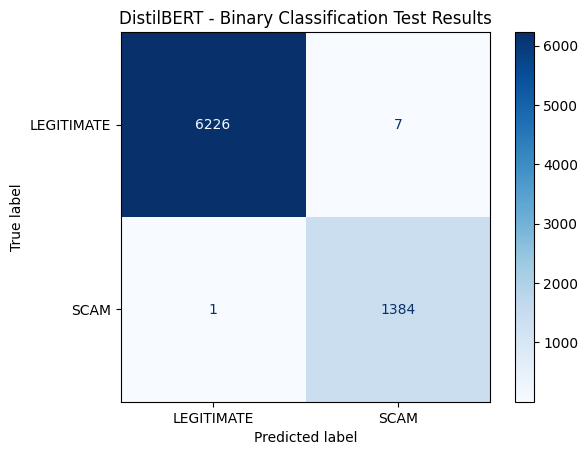

In [31]:
# Generate predictions and confusion matrix on the untouched test set

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

test_predictions = test_trainer.predict(test_dataset)

y_true = test_predictions.label_ids
y_pred = np.argmax(test_predictions.predictions, axis=1)

cm = confusion_matrix(y_true, y_pred)

print("Confusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["LEGITIMATE", "SCAM"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("DistilBERT - Binary Classification Test Results")
plt.show()

In [32]:
# Generate a detailed classification report for the test set

from sklearn.metrics import classification_report

print(
    classification_report(
        y_true,
        y_pred,
        target_names=["LEGITIMATE", "SCAM"],
        digits=5
    )
)

              precision    recall  f1-score   support

  LEGITIMATE    0.99984   0.99888   0.99936      6233
        SCAM    0.99497   0.99928   0.99712      1385

    accuracy                        0.99895      7618
   macro avg    0.99740   0.99908   0.99824      7618
weighted avg    0.99895   0.99895   0.99895      7618




## Final Results and Research Interpretation

### 1. Experimental Summary

A pretrained DistilBERT model (`distilbert/distilbert-base-uncased`) was fine-tuned for binary financial scam detection using the real financial communication corpus.

The experiment used:
- **Training set:** 60,957 records
- **Validation set:** 7,618 records
- **Test set:** 7,618 records
- **Maximum sequence length:** 512 tokens
- **Training epochs:** 3
- **Learning rate:** 2e-5
- **Training batch size:** 16
- **Loss function:** Standard unweighted cross-entropy
- **Model selection criterion:** Validation macro F1

The dataset was divided using the previously established group-aware splitting methodology. Synthetic records were excluded from this binary classification experiment.

### 2. Final Test Performance

The best checkpoint was selected based on validation macro F1 and evaluated on the untouched test set.

| Metric | Score |
|---|---:|
| Accuracy | 99.8950% |
| Scam Precision | 99.4968% |
| Scam Recall | 99.9278% |
| Scam F1-score | 99.7118% |
| Macro F1-score | 99.8238% |
| Weighted F1-score | 99.8950% |
| PR-AUC | 99.9894% |

### 3. Confusion Matrix

| Actual / Predicted | Legitimate | Scam |
|---|---:|---:|
| Legitimate | 6,226 | 7 |
| Scam | 1 | 1,384 |

Out of 7,618 test records, the model correctly classified 7,610 records and misclassified 8.

The model demonstrated high precision and recall for both classes, with only one false negative and seven false positives.

### 4. Validation and Test Consistency

The model achieved a validation macro F1-score of 99.8458% and a test macro F1-score of 99.8238%.

The small difference between these results indicates consistent performance across the validation and held-out test partitions.

However, this consistency should be interpreted within the context of the dataset's source composition and splitting methodology.

### 5. Comparison with Traditional Baselines

The earlier traditional machine learning experiments achieved approximately 99.70% validation accuracy with LinearSVC.

DistilBERT also achieved very high validation performance. Although its results are slightly higher, the difference is relatively small.

Therefore, these results do not establish a substantial performance advantage for Transformer-based modeling over traditional machine learning on this particular binary benchmark.

The motivation for the Transformer-based framework extends beyond binary classification performance to the subsequent multi-level analysis of scam subtypes, fraudulent intent, and social-engineering tactics.

### 6. Limitations and Research Considerations

**Source-related dataset bias**

The scam and legitimate records originate from different datasets and sources. Their vocabulary, formatting, writing styles, and communication structures may contain source-specific patterns correlated with their labels.

Although source metadata was not supplied as a model input, the model may learn these patterns from the message text itself. Group-aware splitting prevents near-duplicate clusters from crossing partitions but does not eliminate source-related shortcuts.

Consequently, the current evaluation does not establish generalization to entirely unseen data sources.

**Sequence-length limitation**

DistilBERT supports a maximum sequence length of 512 tokens. Some records exceed this limit and are truncated during tokenization. Approximately 17.80% of legitimate training messages and 13.98% of scam training messages exceeded 512 tokens.

This may result in the loss of potentially relevant information from longer communications. Long-document handling should be considered in subsequent experiments.

**Dataset representation**

The benchmark reflects the characteristics and composition of the assembled datasets. High performance on this benchmark should not be interpreted as evidence of equivalent performance on real-world communications from previously unseen sources.

### 7. Conclusion

The experiment successfully fine-tuned a pretrained DistilBERT model for binary financial scam detection.

The model achieved 99.8950% test accuracy and 99.8238% macro F1-score on the held-out test partition. Its validation and test results were consistent, demonstrating strong performance under the current experimental setup.

The trained model and tokenizer were saved to persistent Google Drive storage to support reproducibility and subsequent evaluation without repeating the fine-tuning process.

These findings establish the initial Transformer-based binary classification baseline for the proposed research framework.

Further experiments will extend the investigation to financial scam subtype classification, fraudulent intent analysis, and social-engineering tactic recognition, while considering the documented dataset limitations.
